# 05 — Evaluasi footprint

Padanan Tabel 2 dan Fig. 19 paper. Referensi: footprint OSM (pengganti total station).

1. Tiap gedung referensi dipasangkan dengan kandidat (GOB v3, Mask R-CNN) ber-IoU tertinggi.
2. Jarak `d` per pasangan: pergeseran centroid dan jarak rata-rata vertex kandidat ke batas referensi; RMSE (Pers. 2).
3. Distorsi luas (Tabel 2): `(A_ref − A_i) / A_ref × 100%`.
4. Peta pergeseran dan analisis penyebab (relief displacement, bayangan, kanopi).
5. Opsional: referensi GNSS/total station bila ada.

Mask R-CNN dilatih dari OSM, jadi evaluasi yang adil hanya di **area validasi** (`interim/dl_val_area.gpkg`).

**Output**: `output/footprint_eval.csv`, `output/footprint_pairs.gpkg`, peta pergeseran.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from scipy.stats import spearmanr

from ui3d_common import CFG, interim, out, raw, savefig, zonal

F = CFG["footprint"]
ref = gpd.read_file(out("ref_buildings.gpkg"))
cands = {"GOB_v3": gpd.read_file(out("gob_buildings.gpkg"))}
if out("dl_buildings.gpkg").exists():
    cands["MaskRCNN"] = gpd.read_file(out("dl_buildings.gpkg"))
val_area = gpd.read_file(interim("dl_val_area.gpkg")).geometry.iloc[0] if interim("dl_val_area.gpkg").exists() else None
{k: len(v) for k, v in cands.items()}

{'GOB_v3': 1254, 'MaskRCNN': 1803}

## 1–2. Pasangan IoU tertinggi dan jarak

In [2]:
def match(ref, cand):
    j = gpd.sjoin(ref[["geometry"]].reset_index(names="rid"), cand[["geometry"]].reset_index(names="cid"),
                  predicate="intersects")
    rg, cg = ref.geometry.values[j.rid.values], cand.geometry.values[j.cid.values]
    j["iou"] = shapely.area(shapely.intersection(rg, cg)) / shapely.area(shapely.union(rg, cg))
    best = j.sort_values("iou").groupby("rid").tail(1).sort_values("rid")
    rg, cg = ref.geometry.values[best.rid.values], cand.geometry.values[best.cid.values]
    best["shift_centroid_m"] = shapely.distance(shapely.centroid(rg), shapely.centroid(cg))
    best["vertex_dist_m"] = [np.mean(shapely.distance(r.exterior,shapely.points(np.asarray(c.exterior.coords)[:-1])))
                             for r, c in zip(rg, cg)]
    best["area_ref"], best["area_cand"] = shapely.area(rg), shapely.area(cg)
    best["distortion_pct"] = (best.area_ref - best.area_cand) / best.area_ref * 100
    return gpd.GeoDataFrame(best.drop(columns="geometry"), geometry=cg, crs=ref.crs)


def summarize(ref, cand, pairs, name, area):
    p = pairs[pairs.iou >= F["match_iou"]]
    rmse = lambda d: float(np.sqrt(np.mean(np.square(d)))) if len(d) else np.nan  # noqa: E731
    return dict(sumber=name, area=area, n_ref=len(ref), n_kandidat=len(cand), n_pasangan=len(p),
                tingkat_deteksi_pct=len(p) / max(len(ref), 1) * 100, iou_median=p.iou.median(),
                rmse_centroid_m=rmse(p.shift_centroid_m), rmse_vertex_m=rmse(p.vertex_dist_m),
                distorsi_pasangan_pct=(p.area_ref.sum() - p.area_cand.sum()) / p.area_ref.sum() * 100 if len(p) else np.nan,
                distorsi_total_pct=(ref.area.sum() - cand.area.sum()) / ref.area.sum() * 100)


rows, all_pairs = [], []
for name, cand in cands.items():
    areas = [("AOI", None)] + ([("val", val_area)] if val_area is not None else [])
    for area_name, geom in areas:
        r = ref if geom is None else ref[ref.centroid.within(geom)]
        c = cand if geom is None else cand[cand.centroid.within(geom)]
        pairs = match(r.reset_index(drop=True), c.reset_index(drop=True))
        rows.append(summarize(r, c, pairs, name, area_name))
        if area_name == "AOI":
            all_pairs.append(pairs.assign(sumber=name))
ev = pd.DataFrame(rows).round(3)
ev.to_csv(out("footprint_eval.csv"), index=False)
print(f"Paper: digitasi manual RMSE 3,7 m, distorsi 4,61%; deep learning distorsi 17,12%. Pasangan: IoU >= {F['match_iou']}")
ev

Paper: digitasi manual RMSE 3,7 m, distorsi 4,61%; deep learning distorsi 17,12%. Pasangan: IoU >= 0.3


,sumber,area,n_ref,n_kandidat,n_pasangan,tingkat_deteksi_pct,iou_median,rmse_centroid_m,rmse_vertex_m,distorsi_pasangan_pct,distorsi_total_pct
0,GOB_v3,AOI,995,1254,516,51.859,0.519,5.675,3.722,-0.357,-7.204
1,GOB_v3,val,249,320,131,52.610,0.517,5.261,3.863,-4.883,-7.177
2,MaskRCNN,AOI,995,1803,281,28.241,0.629,6.406,3.425,11.417,-155.251
3,MaskRCNN,val,249,168,63,25.301,0.672,7.490,4.548,-6.279,-55.117


In [3]:
pairs = pd.concat(all_pairs, ignore_index=True)
pairs = gpd.GeoDataFrame(pairs, geometry="geometry", crs=ref.crs)
pairs.to_file(out("footprint_pairs.gpkg"), layer="pairs")

## Peta pergeseran (setara Fig. 19)

Panah = pergeseran centroid referensi → kandidat (dibesarkan 5×). Zoom 400 × 400 m di sekitar gedung OSM terbesar.

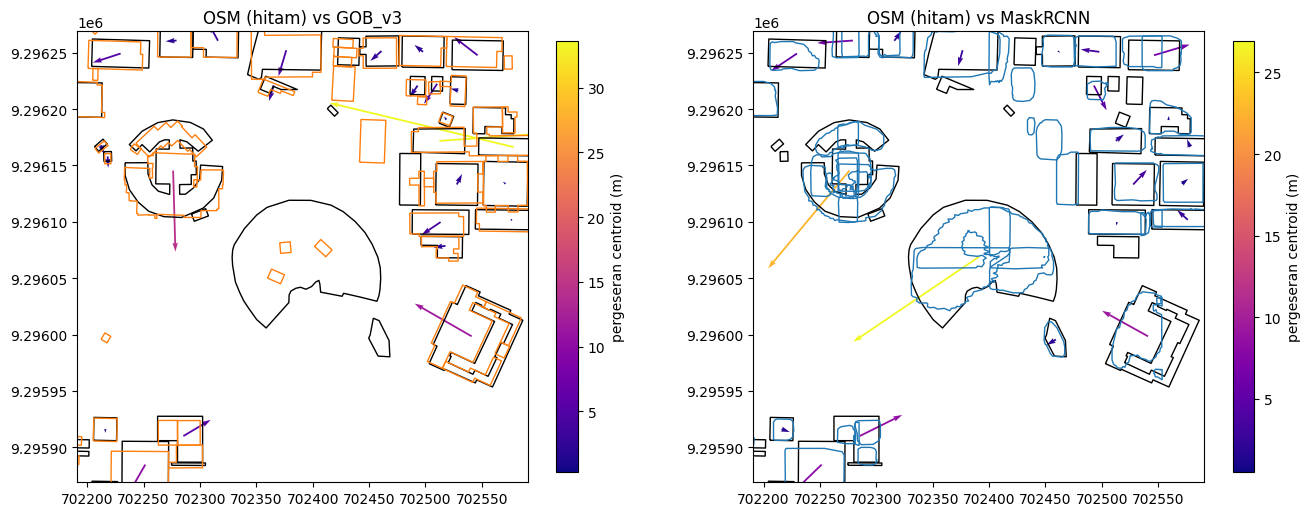

In [4]:
cx, cy = ref.loc[ref.area.idxmax()].geometry.centroid.coords[0]
ext = (cx - 200, cy - 200, cx + 200, cy + 200)
colors = {"GOB_v3": "tab:orange", "MaskRCNN": "tab:blue"}
fig, axs = plt.subplots(1, len(cands), figsize=(8 * len(cands), 8), squeeze=False)
for a, name in zip(axs[0], cands):
    p = pairs[(pairs.sumber == name) & (pairs.iou >= F["match_iou"])].cx[ext[0]:ext[2], ext[1]:ext[3]]
    ref.cx[ext[0]:ext[2], ext[1]:ext[3]].boundary.plot(ax=a, color="k", lw=1)
    cands[name].cx[ext[0]:ext[2], ext[1]:ext[3]].boundary.plot(ax=a, color=colors[name], lw=1)
    rc = shapely.centroid(ref.geometry.values[p.rid.values])
    pc = shapely.centroid(p.geometry.values)
    x, y = shapely.get_x(rc), shapely.get_y(rc)
    q = a.quiver(x, y, (shapely.get_x(pc) - x) * 5, (shapely.get_y(pc) - y) * 5, p.shift_centroid_m,
                 angles="xy", scale_units="xy", scale=1, cmap="plasma", width=0.004)
    plt.colorbar(q, ax=a, label="pergeseran centroid (m)", shrink=0.7)
    a.set(xlim=(ext[0], ext[2]), ylim=(ext[1], ext[3]), title=f"OSM (hitam) vs {name}")
    a.set_aspect("equal")
savefig(fig, "fig19_pergeseran.png")
plt.show()

## Analisis penyebab

- **Relief displacement atap**: citra satelit off-nadir menggeser atap gedung tinggi menjauhi titik nadir.
  Bila ini dominan, pergeseran naik dengan tinggi gedung (tinggi dari Open Buildings 2.5D) dan arahnya seragam.
- **Bayangan** memperbesar footprint ke satu arah (distorsi luas negatif); **kanopi pohon** memotong footprint
  (distorsi positif, gedung hilang). Periksa visual di peta pergeseran dan contoh deteksi notebook 04.

In [5]:
h = zonal(ref, raw("gob_25d"), np.median, band=2)
for name in cands:
    p = pairs[(pairs.sumber == name) & (pairs.iou >= F["match_iou"])]
    hh = h[p.rid.values]
    ok = np.isfinite(hh)
    rho, pv = spearmanr(hh[ok], p.shift_centroid_m.values[ok])
    dx = shapely.get_x(shapely.centroid(p.geometry.values)) - shapely.get_x(shapely.centroid(ref.geometry.values[p.rid.values]))
    dy = shapely.get_y(shapely.centroid(p.geometry.values)) - shapely.get_y(shapely.centroid(ref.geometry.values[p.rid.values]))
    print(f"{name}: Spearman(tinggi, pergeseran) = {rho:.2f} (p={pv:.3f}); "
          f"rata-rata vektor geser dx={dx.mean():.2f} m, dy={dy.mean():.2f} m; "
          f"distorsi median {p.distortion_pct.median():.1f}%")

GOB_v3: Spearman(tinggi, pergeseran) = 0.19 (p=0.000); rata-rata vektor geser dx=-0.61 m, dy=-0.92 m; distorsi median -7.6%
MaskRCNN: Spearman(tinggi, pergeseran) = 0.17 (p=0.004); rata-rata vektor geser dx=-0.59 m, dy=-0.63 m; distorsi median 1.0%


## Opsional: referensi GNSS RTK / total station

Bila ada titik sudut gedung hasil survei di `raw/gnss_corners.gpkg` (titik, CRS apa pun), sel ini menghitung
RMSE jarak tiap titik ke vertex OSM terdekat, sehingga OSM ikut dievaluasi.

In [6]:
gnss_path = raw("osm").parent / "gnss_corners.gpkg"
if gnss_path.exists():
    gnss = gpd.read_file(gnss_path).to_crs(ref.crs)
    verts = shapely.points(np.vstack([np.asarray(g.exterior.coords) for g in ref.geometry]))
    tree = shapely.STRtree(verts)
    d = shapely.distance(gnss.geometry.values, verts[tree.nearest(gnss.geometry.values)])
    print(f"OSM vs GNSS: n={len(d)}, RMSE={np.sqrt(np.mean(d ** 2)):.2f} m, maks={d.max():.2f} m")
else:
    print("Tidak ada raw/gnss_corners.gpkg — dilewati")

Tidak ada raw/gnss_corners.gpkg — dilewati
